<a href="https://colab.research.google.com/github/sastha-06/24ADI006_DL_24BAD106/blob/main/24BAD106_DL_LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#from google.colab import files
#uploaded = files.upload()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("SASTHA JEYASRI A_24BAD106")

df = pd.read_csv("breast-cancer.csv")

print("\nFirst 5 Rows")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nDataset Information")
print(df.info())

print("\nStatistical Summary")
print(df.describe())

print("\nMissing Values")
print(df.isnull().sum())

SASTHA JEYASRI A_24BAD106

First 5 Rows
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  

In [3]:
label_encoder = LabelEncoder()

df["diagnosis"] = label_encoder.fit_transform(df["diagnosis"])

X = df[[
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "compactness_mean",
    "concavity_mean",
    "concave points_mean",
    "radius_worst",
    "perimeter_worst",
    "area_worst"
]]

y = df["diagnosis"]

print("\nSelected Features")
print(X.columns)

print("\nTarget")
print(y.name)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Selected Features
Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'compactness_mean', 'concavity_mean', 'concave points_mean',
       'radius_worst', 'perimeter_worst', 'area_worst'],
      dtype='object')

Target
diagnosis


**PART A: VISUALIZATION OF ACTIVATION FUNCTIONS**

SASTHA JEYASRI A_24BAD106


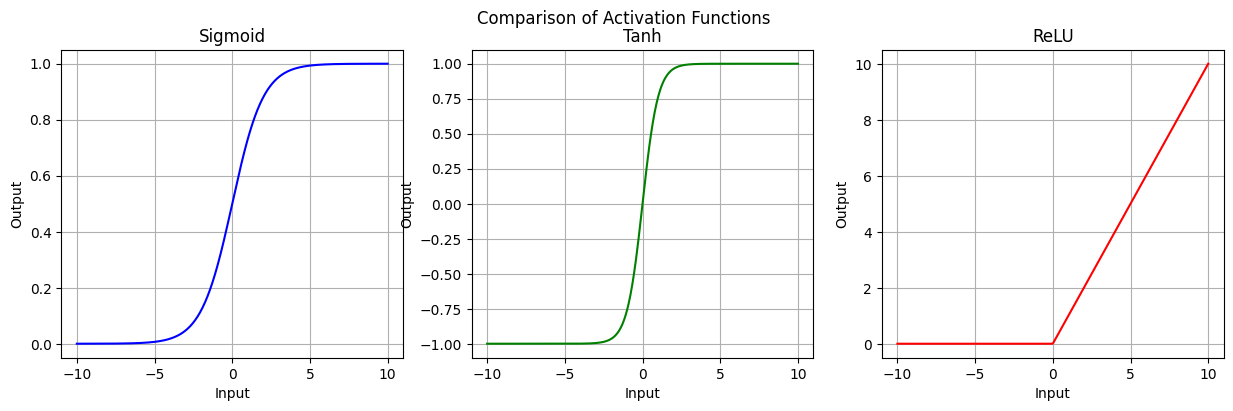

In [24]:
x = np.linspace(-10, 10, 500)
print("SASTHA JEYASRI A_24BAD106")
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.plot(x, sigmoid, color="blue")
plt.title("Sigmoid")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

plt.subplot(1,3,2)
plt.plot(x, tanh, color="green")
plt.title("Tanh")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

plt.subplot(1,3,3)
plt.plot(x, relu, color="red")
plt.title("ReLU")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

plt.suptitle("Comparison of Activation Functions")
plt.show()

**PART B: PERFORMANCE COMPARISON OF ACTIVATION FUNCTIONS**

In [25]:
activations = ["sigmoid", "tanh", "relu"]
print("SASTHA JEYASRI A_24BAD106")
history_dict = {}
models = {}

for activation in activations:

    print("\nTraining ANN using", activation)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(16, activation=activation),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=30,
        batch_size=32,
        verbose=1
    )

    history_dict[activation] = history
    models[activation] = model

SASTHA JEYASRI A_24BAD106

Training ANN using sigmoid
Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.3846 - loss: 1.0125 - val_accuracy: 0.3297 - val_loss: 0.9946
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3846 - loss: 0.8853 - val_accuracy: 0.3297 - val_loss: 0.8660
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3846 - loss: 0.7869 - val_accuracy: 0.3297 - val_loss: 0.7651
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3846 - loss: 0.7076 - val_accuracy: 0.3297 - val_loss: 0.6911
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5687 - loss: 0.6517 - val_accuracy: 0.8352 - val_loss: 0.6348
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9396 - loss: 0.6115 - val_accuracy: 0.9231 - val_loss: 0.5915
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8736 - loss: 0.5788 - val_accuracy: 0.8791 - val_loss: 0.5578
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accurac

SASTHA JEYASRI A_24BAD106


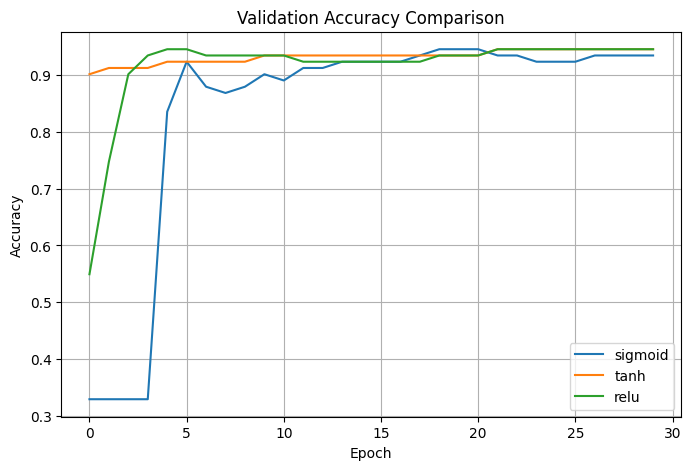

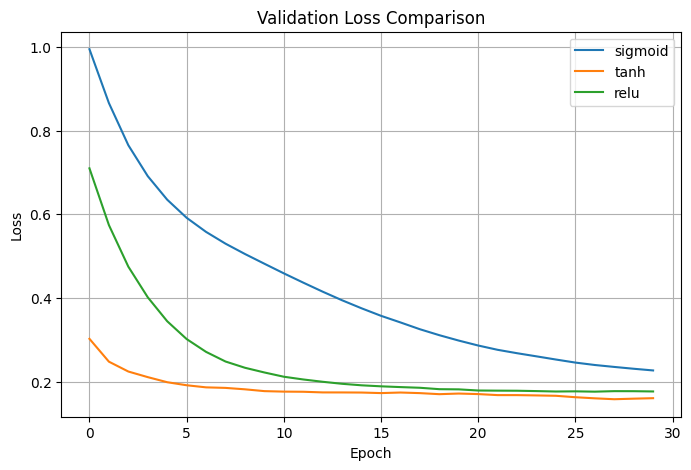

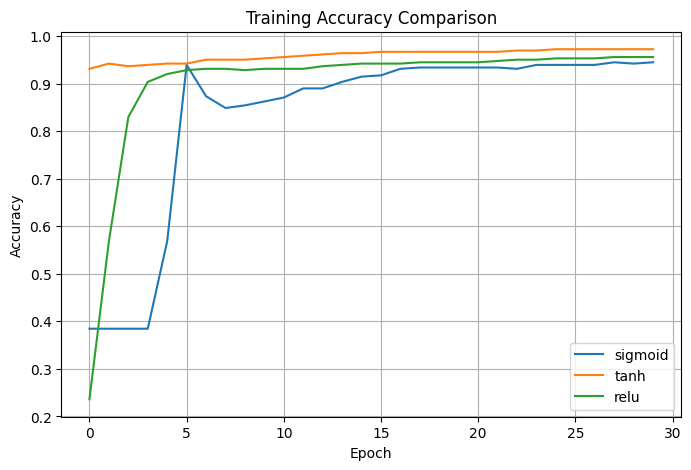

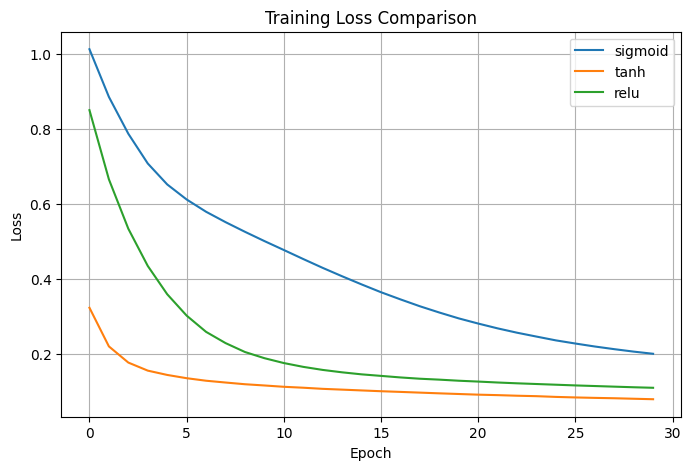


Activation Function Comparison

--------------------------------------
Activation Function : sigmoid
Training Accuracy   : 0.9451
Validation Accuracy : 0.9341
Training Loss       : 0.1998
Validation Loss     : 0.2265
Epochs              : 30
--------------------------------------
Activation Function : tanh
Training Accuracy   : 0.9725
Validation Accuracy : 0.9451
Training Loss       : 0.0785
Validation Loss     : 0.1602
Epochs              : 30
--------------------------------------
Activation Function : relu
Training Accuracy   : 0.956
Validation Accuracy : 0.9451
Training Loss       : 0.109
Validation Loss     : 0.1762
Epochs              : 30
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Model Evaluation (ReLU)

Accuracy : 0.9649
Precision: 0.975
Recall   : 0.9286
F1 Score : 0.9512

Confusion Matrix
[[71  1]
 [ 3 39]]


In [26]:
plt.figure(figsize=(8,5))
print("SASTHA JEYASRI A_24BAD106")
for activation in activations:
    plt.plot(
        history_dict[activation].history["val_accuracy"],
        label=activation
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

plt.figure(figsize=(8,5))

for activation in activations:
    plt.plot(
        history_dict[activation].history["val_loss"],
        label=activation
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

plt.figure(figsize=(8,5))

for activation in activations:
    plt.plot(
        history_dict[activation].history["accuracy"],
        label=activation
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(8,5))

for activation in activations:
    plt.plot(
        history_dict[activation].history["loss"],
        label=activation
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

print("\nActivation Function Comparison\n")

for activation in activations:

    train_acc = history_dict[activation].history["accuracy"][-1]
    val_acc = history_dict[activation].history["val_accuracy"][-1]

    train_loss = history_dict[activation].history["loss"][-1]
    val_loss = history_dict[activation].history["val_loss"][-1]

    epochs = len(history_dict[activation].history["accuracy"])

    print("--------------------------------------")
    print("Activation Function :", activation)
    print("Training Accuracy   :", round(train_acc,4))
    print("Validation Accuracy :", round(val_acc,4))
    print("Training Loss       :", round(train_loss,4))
    print("Validation Loss     :", round(val_loss,4))
    print("Epochs              :", epochs)


best_model = models["relu"]

y_pred_prob = best_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nModel Evaluation (ReLU)\n")

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

print("\nConfusion Matrix")

print(cm)

**PART C: COMPARISON OF OPTIMIZATION ALGORITHMS**

In [27]:
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
print("SASTHA JEYASRI A_24BAD106")
optimizers = {
    "SGD": SGD(learning_rate=0.01),
    "Momentum": SGD(learning_rate=0.01, momentum=0.9),
    "RMSProp": RMSprop(learning_rate=0.001),
    "Adam": Adam(learning_rate=0.001)
}

optimizer_history = {}
optimizer_models = {}

for name, optimizer in optimizers.items():

    print("\nTraining using", name)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=30,
        batch_size=32,
        verbose=1
    )

    optimizer_history[name] = history
    optimizer_models[name] = model

SASTHA JEYASRI A_24BAD106

Training using SGD
Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.5989 - loss: 0.6653 - val_accuracy: 0.6923 - val_loss: 0.6302
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7005 - loss: 0.6061 - val_accuracy: 0.7692 - val_loss: 0.5851
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7912 - loss: 0.5636 - val_accuracy: 0.8462 - val_loss: 0.5477
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8764 - loss: 0.5287 - val_accuracy: 0.8791 - val_loss: 0.5163
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8984 - loss: 0.4971 - val_accuracy: 0.8791 - val_loss: 0.4876
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9176 - loss: 0.4679 - val_accuracy: 0.9011 - val_loss: 0.4609
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9231 - loss: 0.4398 - val_accuracy: 0.9121 - val_loss: 0.4361
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.

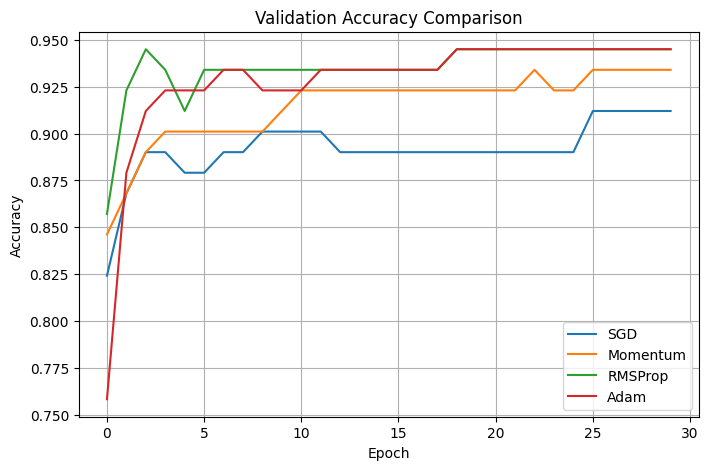

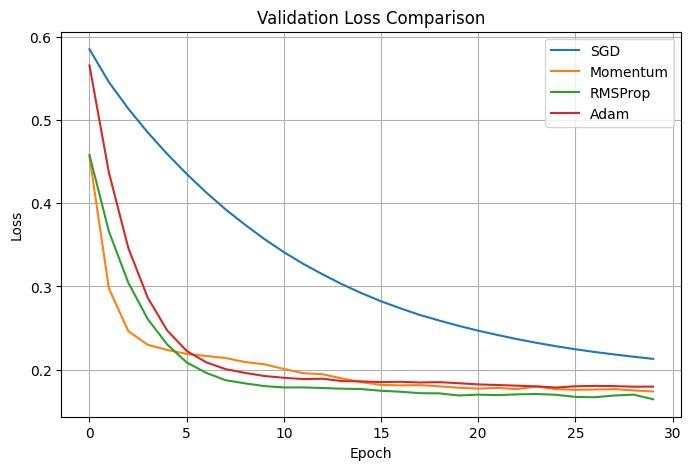

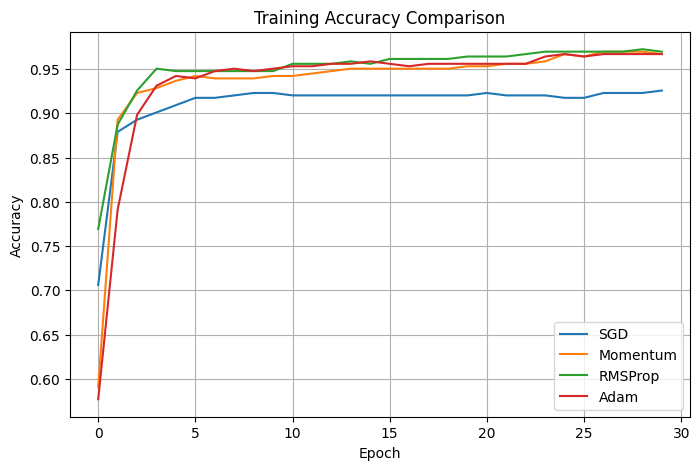

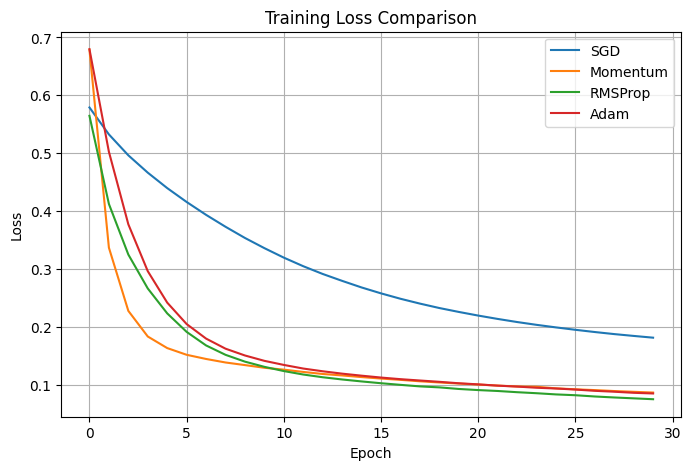


Optimizer Comparison

--------------------------------------------
Optimizer : SGD
Training Accuracy   : 0.9258
Validation Accuracy : 0.9121
Training Loss       : 0.1815
Validation Loss     : 0.2129
Epochs              : 30
--------------------------------------------
Optimizer : Momentum
Training Accuracy   : 0.967
Validation Accuracy : 0.9341
Training Loss       : 0.0868
Validation Loss     : 0.1737
Epochs              : 30
--------------------------------------------
Optimizer : RMSProp
Training Accuracy   : 0.9698
Validation Accuracy : 0.9451
Training Loss       : 0.0753
Validation Loss     : 0.1644
Epochs              : 30
--------------------------------------------
Optimizer : Adam
Training Accuracy   : 0.967
Validation Accuracy : 0.9451
Training Loss       : 0.0852
Validation Loss     : 0.1795
Epochs              : 30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

Final Model Evaluation (Adam)

Accuracy : 0.9737
Precision: 0.9756
Recall   : 0.9524
F1 Score : 0.9639

Confusion Matrix
[

In [20]:
plt.figure(figsize=(8,5))
print("SASTHA JEYASRI A_24BAD106")
for name in optimizers:
    plt.plot(
        optimizer_history[name].history["val_accuracy"],
        label=name
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))

for name in optimizers:
    plt.plot(
        optimizer_history[name].history["val_loss"],
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))

for name in optimizers:
    plt.plot(
        optimizer_history[name].history["accuracy"],
        label=name
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))

for name in optimizers:
    plt.plot(
        optimizer_history[name].history["loss"],
        label=name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nOptimizer Comparison\n")

for name in optimizers:

    train_acc = optimizer_history[name].history["accuracy"][-1]
    val_acc = optimizer_history[name].history["val_accuracy"][-1]

    train_loss = optimizer_history[name].history["loss"][-1]
    val_loss = optimizer_history[name].history["val_loss"][-1]

    epochs = len(optimizer_history[name].history["accuracy"])

    print("--------------------------------------------")
    print("Optimizer :", name)
    print("Training Accuracy   :", round(train_acc,4))
    print("Validation Accuracy :", round(val_acc,4))
    print("Training Loss       :", round(train_loss,4))
    print("Validation Loss     :", round(val_loss,4))
    print("Epochs              :", epochs)

best_optimizer_model = optimizer_models["Adam"]

y_pred_prob = best_optimizer_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\nFinal Model Evaluation (Adam)\n")

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

print("\nConfusion Matrix")
print(cm)




**PART D: DEEP LEARNING EXPERIMENT MANAGEMENT**

In [21]:
model.save("best_ann_model.keras")

print("Model Saved Successfully")

Model Saved Successfully


In [22]:
from google.colab import drive

drive.mount('/content/drive')
model.save("/content/drive/MyDrive/best_ann_model.keras")

Mounted at /content/drive
